In [4]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, f1_score

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2, ResNet50
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess


In [5]:
BASE_PATH = "/kaggle/input/skin-diseases-image-dataset/IMG_CLASSES"

classes = {
    "Melanoma": os.path.join(BASE_PATH, "2. Melanoma 15.75k"),
    "BCC": os.path.join(BASE_PATH, "4. Basal Cell Carcinoma (BCC) 3323"),
    "Seborrheic_Keratosis": os.path.join(BASE_PATH, "8. Seborrheic Keratoses and other Benign Tumors - 1.8k"),
    "Tinea": os.path.join(BASE_PATH, "9. Tinea Ringworm Candidiasis and other Fungal Infections - 1.7k"),
    "Eczema": os.path.join(BASE_PATH, "1. Eczema 1677"),
}

In [6]:
IMG_SIZE = 224
data = []
labels = []

for label, path in classes.items():
    images = os.listdir(path)
    total_images = len(images)
    
    print(f"{label}: {total_images} images found")

    # Downsample only if images are more than 4000
    if label == "Melanoma":
        sample_size = min(4000, total_images)
        images = random.sample(images, sample_size)

    for img in images:
        img_path = os.path.join(path, img)
        data.append(img_path)
        labels.append(label)

df = pd.DataFrame({"image": data, "label": labels})
print("\nFinal Class Distribution:")
print(df["label"].value_counts())


Melanoma: 3140 images found
BCC: 3323 images found
Seborrheic_Keratosis: 1847 images found
Tinea: 1702 images found
Eczema: 1677 images found

Final Class Distribution:
label
BCC                     3323
Melanoma                3140
Seborrheic_Keratosis    1847
Tinea                   1702
Eczema                  1677
Name: count, dtype: int64


In [7]:
train_df, test_df = train_test_split(df, test_size=0.15, stratify=df["label"], random_state=42)
train_df, val_df = train_test_split(train_df, test_size=0.15, stratify=train_df["label"], random_state=42)

print("Train:", len(train_df))
print("Val:", len(val_df))
print("Test:", len(test_df))

Train: 8444
Val: 1491
Test: 1754


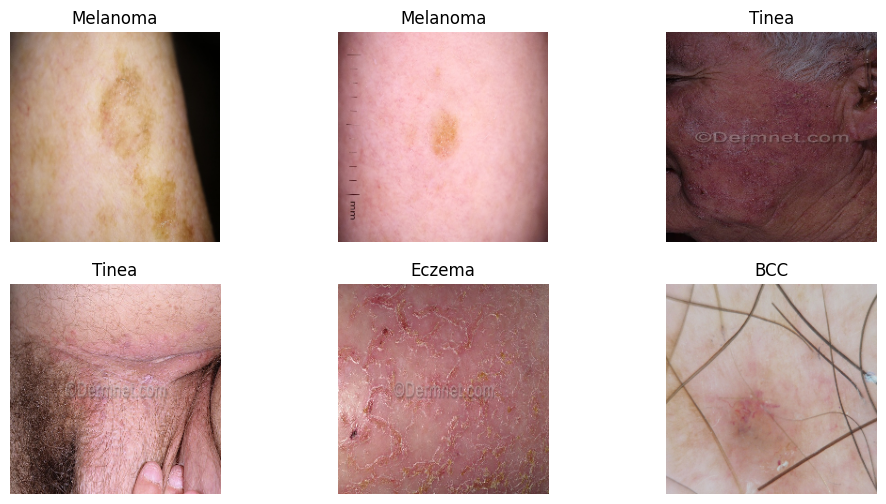

In [8]:
def load_image(path):
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    return img

# Show sample processed images
plt.figure(figsize=(12,6))
for i in range(6):
    img = load_image(train_df.iloc[i]["image"])
    plt.subplot(2,3,i+1)
    plt.imshow(img)
    plt.title(train_df.iloc[i]["label"])
    plt.axis("off")
plt.show()

In [12]:
# Create label map (stable & sorted)
label_names = sorted(df["label"].unique())
label_map = {name: idx for idx, name in enumerate(label_names)}

print("Label Map:", label_map)


# Convert dataframe labels to numeric
train_df["label_idx"] = train_df["label"].map(label_map)
val_df["label_idx"] = val_df["label"].map(label_map)
test_df["label_idx"] = test_df["label"].map(label_map)


IMG_SIZE = 224
BATCH_SIZE = 32


# TensorFlow image loading function (NO py_function)
def decode_img(img_path, label):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32) / 255.0
    return img, label


# Dataset builder
def make_dataset(dataframe, batch=BATCH_SIZE, shuffle=True):
    paths = dataframe["image"].values
    labels = dataframe["label_idx"].values

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if shuffle:
        ds = ds.shuffle(buffer_size=len(dataframe))

    ds = ds.map(decode_img, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds


# Create datasets
train_ds = make_dataset(train_df, shuffle=True)
val_ds = make_dataset(val_df, shuffle=False)
test_ds = make_dataset(test_df, shuffle=False)

print("Datasets ready ✔")


Label Map: {'BCC': 0, 'Eczema': 1, 'Melanoma': 2, 'Seborrheic_Keratosis': 3, 'Tinea': 4}
Datasets ready ✔


In [13]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_df["label_idx"]),
    y=train_df["label_idx"]
)

class_weights = dict(enumerate(class_weights))
print("Class Weights:", class_weights)

Class Weights: {0: np.float64(0.7036666666666667), 1: np.float64(1.3945499587118084), 2: np.float64(0.7442926399294844), 3: np.float64(1.265967016491754), 4: np.float64(1.3730081300813008)}


In [14]:
def build_custom_cnn():
    model = models.Sequential([
        layers.Input(shape=(224, 224, 3)),

        layers.Conv2D(32, (3,3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Conv2D(64, (3,3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Conv2D(128, (3,3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.5),

        layers.Dense(len(label_map), activation='softmax')
    ])
    return model


cnn_model = build_custom_cnn()

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


# ===============================
# Callbacks (Prevent Overfitting)
# ===============================

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.3,
        patience=2,
        verbose=1
    )
]


# ===============================
# Train Model
# ===============================

history_cnn = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    class_weight=class_weights,
    callbacks=callbacks
)


Epoch 1/20


I0000 00:00:1771035881.064698     131 service.cc:152] XLA service 0x7e0fac0a5cc0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1771035881.064740     131 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1771035881.064744     131 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1771035881.683129     131 cuda_dnn.cc:529] Loaded cuDNN version 91002


  2/264 ━━━━━━━━━━━━━━━━━━━━ 21s 84ms/step - accuracy: 0.2812 - loss: 10.4817

I0000 00:00:1771035888.324576     131 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


264/264 ━━━━━━━━━━━━━━━━━━━━ 54s 168ms/step - accuracy: 0.4403 - loss: 11.9547 - val_accuracy: 0.4634 - val_loss: 24.9661 - learning_rate: 0.0010
Epoch 2/20
264/264 ━━━━━━━━━━━━━━━━━━━━ 20s 77ms/step - accuracy: 0.4214 - loss: 1.2657 - val_accuracy: 0.6043 - val_loss: 1.3175 - learning_rate: 0.0010
Epoch 3/20
264/264 ━━━━━━━━━━━━━━━━━━━━ 21s 78ms/step - accuracy: 0.4777 - loss: 1.1966 - val_accuracy: 0.6506 - val_loss: 0.7306 - learning_rate: 0.0010
Epoch 4/20
264/264 ━━━━━━━━━━━━━━━━━━━━ 21s 77ms/step - accuracy: 0.5175 - loss: 1.1494 - val_accuracy: 0.5111 - val_loss: 1.2014 - learning_rate: 0.0010
Epoch 5/20
264/264 ━━━━━━━━━━━━━━━━━━━━ 21s 78ms/step - accuracy: 0.5360 - loss: 1.1415 - val_accuracy: 0.6553 - val_loss: 0.6792 - learning_rate: 0.0010
Epoch 6/20
264/264 ━━━━━━━━━━━━━━━━━━━━ 20s 77ms/step - accuracy: 0.5382 - loss: 1.0964 - val_accuracy: 0.6351 - val_loss: 0.8668 - learning_rate: 0.0010
Epoch 7/20
264/264 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.5529 - loss: 1.06

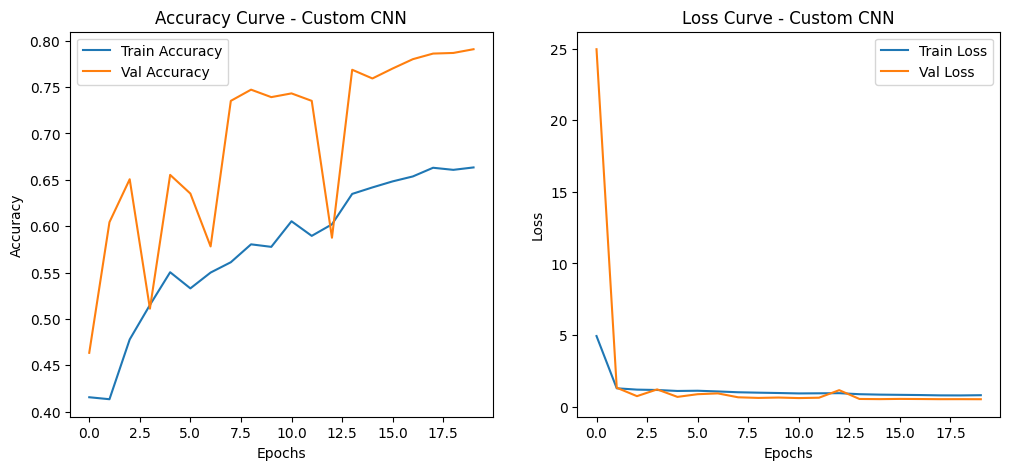

In [15]:
# ===============================
# Plot Training Curves
# ===============================

plt.figure(figsize=(12,5))

# Accuracy
plt.subplot(1,2,1)
plt.plot(history_cnn.history['accuracy'], label='Train Accuracy')
plt.plot(history_cnn.history['val_accuracy'], label='Val Accuracy')
plt.title("Accuracy Curve - Custom CNN")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1,2,2)
plt.plot(history_cnn.history['loss'], label='Train Loss')
plt.plot(history_cnn.history['val_loss'], label='Val Loss')
plt.title("Loss Curve - Custom CNN")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 603ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━

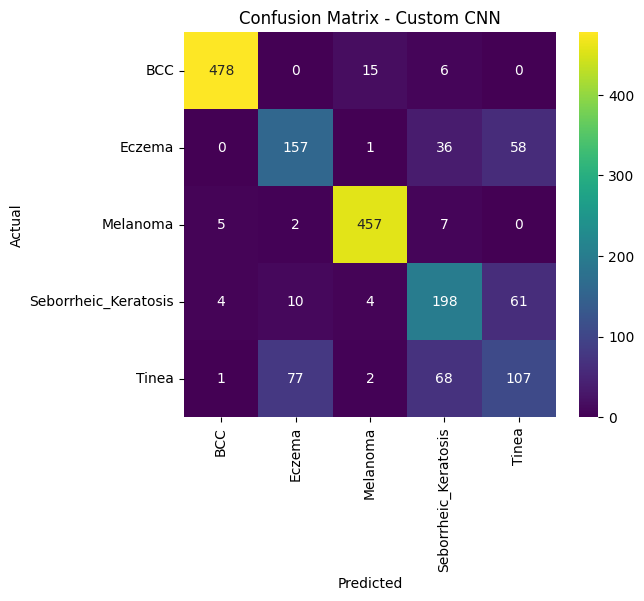

In [16]:
# ===============================
# Evaluate Custom CNN on Test Set
# ===============================

y_true = []
y_pred = []

for images, labels in test_ds:
    preds = cnn_model.predict(images)
    preds = np.argmax(preds, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(preds)

print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=label_names))

macro_f1 = f1_score(y_true, y_pred, average='macro')
print("Macro F1 Score:", macro_f1)


# ===============================
# Confusion Matrix
# ===============================

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='viridis',
            xticklabels=label_names,
            yticklabels=label_names)
plt.title("Confusion Matrix - Custom CNN")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step


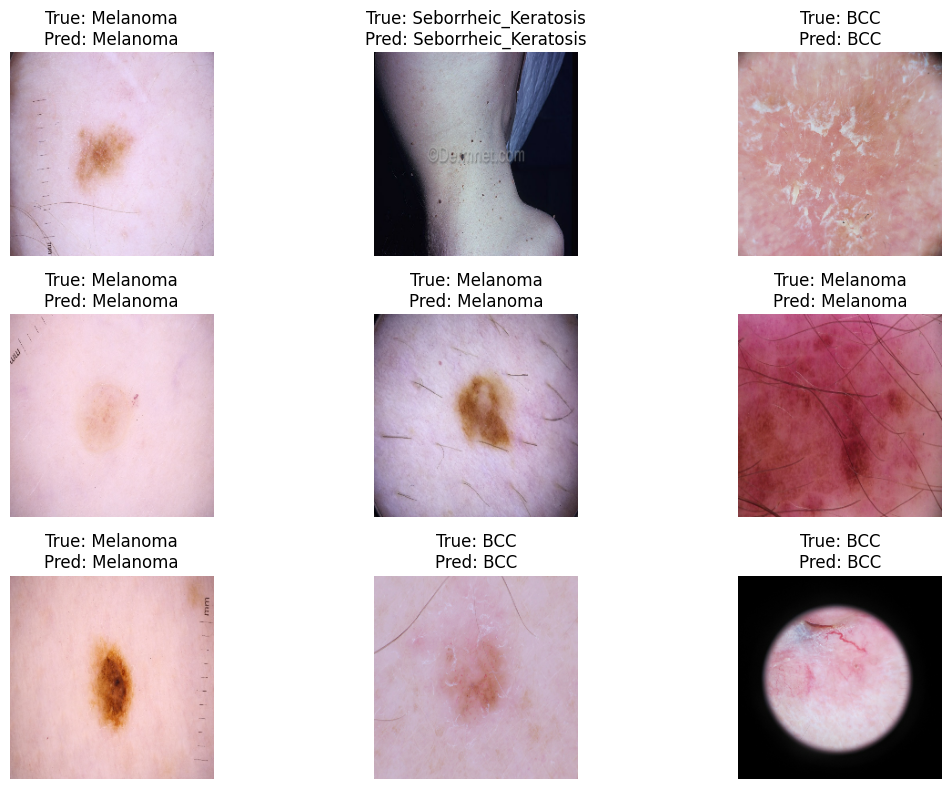

In [17]:
# ===============================
# Show Sample Predictions
# ===============================

images, labels = next(iter(test_ds))
preds = cnn_model.predict(images)
preds = np.argmax(preds, axis=1)

plt.figure(figsize=(12,8))

for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(images[i])
    plt.title(f"True: {label_names[labels[i]]}\nPred: {label_names[preds[i]]}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [18]:
cnn_model.save("custom_cnn_skin_model.keras")
print("Custom CNN model saved successfully ✔")

Custom CNN model saved successfully ✔


In [25]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# ===============================
# Rebuild dataset with MobileNet preprocessing
# ===============================

def decode_img_mobilenet(img_path, label):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [224, 224])
    img = preprocess_input(img)   # <-- IMPORTANT
    return img, label

def make_dataset_mobilenet(dataframe, batch=32, shuffle=True):
    paths = dataframe["image"].values
    labels = dataframe["label_idx"].values

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if shuffle:
        ds = ds.shuffle(buffer_size=len(dataframe))

    ds = ds.map(decode_img_mobilenet, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds


train_ds_mob = make_dataset_mobilenet(train_df, shuffle=True)
val_ds_mob = make_dataset_mobilenet(val_df, shuffle=False)
test_ds_mob = make_dataset_mobilenet(test_df, shuffle=False)


# ===============================
# Build Improved MobileNet Model
# ===============================

base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

base_model.trainable = False   # First phase: freeze

for layer in base_model.layers[:-30]:
    layer.trainable = False

mobilenet_model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.BatchNormalization(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(len(label_map), activation='softmax')
])


mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.3,
        patience=2,
        verbose=1
    )
]


history_mobilenet = mobilenet_model.fit(
    train_ds_mob,
    validation_data=val_ds_mob,
    epochs=15,
    class_weight=class_weights,
    callbacks=callbacks
)


Epoch 1/15
264/264 ━━━━━━━━━━━━━━━━━━━━ 39s 115ms/step - accuracy: 0.2203 - loss: 2.4899 - val_accuracy: 0.4541 - val_loss: 1.3009 - learning_rate: 1.0000e-05
Epoch 2/15
264/264 ━━━━━━━━━━━━━━━━━━━━ 19s 72ms/step - accuracy: 0.4046 - loss: 1.7295 - val_accuracy: 0.6452 - val_loss: 0.9563 - learning_rate: 1.0000e-05
Epoch 3/15
264/264 ━━━━━━━━━━━━━━━━━━━━ 19s 72ms/step - accuracy: 0.5287 - loss: 1.4035 - val_accuracy: 0.7082 - val_loss: 0.7883 - learning_rate: 1.0000e-05
Epoch 4/15
264/264 ━━━━━━━━━━━━━━━━━━━━ 19s 72ms/step - accuracy: 0.5827 - loss: 1.2502 - val_accuracy: 0.7290 - val_loss: 0.6995 - learning_rate: 1.0000e-05
Epoch 5/15
264/264 ━━━━━━━━━━━━━━━━━━━━ 19s 72ms/step - accuracy: 0.6275 - loss: 1.1627 - val_accuracy: 0.7485 - val_loss: 0.6419 - learning_rate: 1.0000e-05
Epoch 6/15
264/264 ━━━━━━━━━━━━━━━━━━━━ 19s 72ms/step - accuracy: 0.6506 - loss: 1.0859 - val_accuracy: 0.7572 - val_loss: 0.6038 - learning_rate: 1.0000e-05
Epoch 7/15
264/264 ━━━━━━━━━━━━━━━━━━━━ 19s 73ms/st

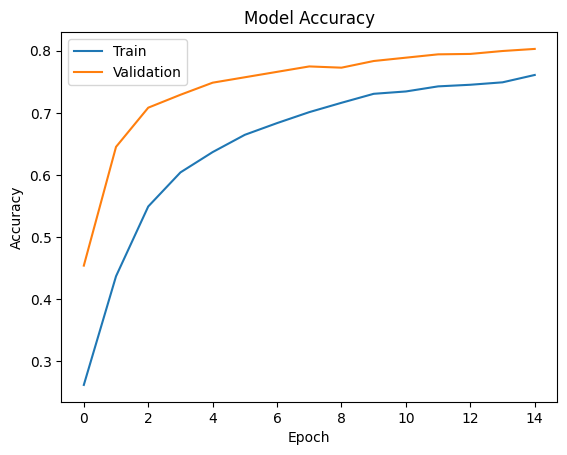

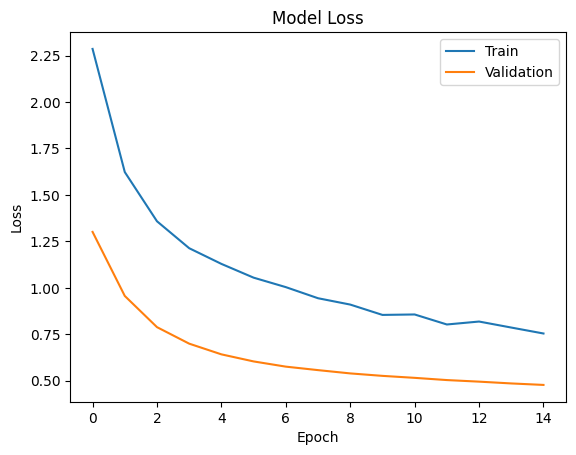

In [26]:
import matplotlib.pyplot as plt

# Accuracy
plt.figure()
plt.plot(history_mobilenet.history['accuracy'])
plt.plot(history_mobilenet.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'])
plt.show()

# Loss
plt.figure()
plt.plot(history_mobilenet.history['loss'])
plt.plot(history_mobilenet.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'])
plt.show()


55/55 ━━━━━━━━━━━━━━━━━━━━ 6s 118ms/step - accuracy: 0.7809 - loss: 0.5847
Test Accuracy: 0.7730900645256042
55/55 ━━━━━━━━━━━━━━━━━━━━ 12s 143ms/step
F1 Score: 0.7672005840372286

Classification Report:

              precision    recall  f1-score   support

           0       0.93      0.91      0.92       499
           1       0.57      0.70      0.63       252
           2       0.90      0.93      0.91       471
           3       0.62      0.71      0.66       277
           4       0.61      0.36      0.45       255

    accuracy                           0.77      1754
   macro avg       0.73      0.72      0.72      1754
weighted avg       0.77      0.77      0.77      1754



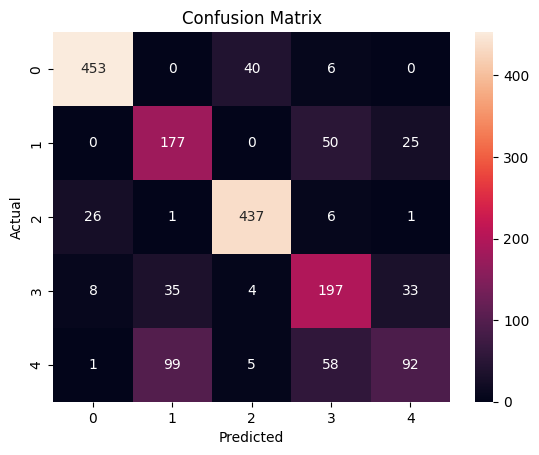

In [27]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import numpy as np
import seaborn as sns

# Evaluate
test_loss, test_acc = mobilenet_model.evaluate(test_ds)
print("Test Accuracy:", test_acc)

# Predictions
y_true = np.concatenate([y for x, y in test_ds], axis=0)
y_pred_probs = mobilenet_model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)

# F1 Score
f1 = f1_score(y_true, y_pred, average='weighted')
print("F1 Score:", f1)

# Classification Report
print("\nClassification Report:\n")
print(classification_report(y_true, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure()
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


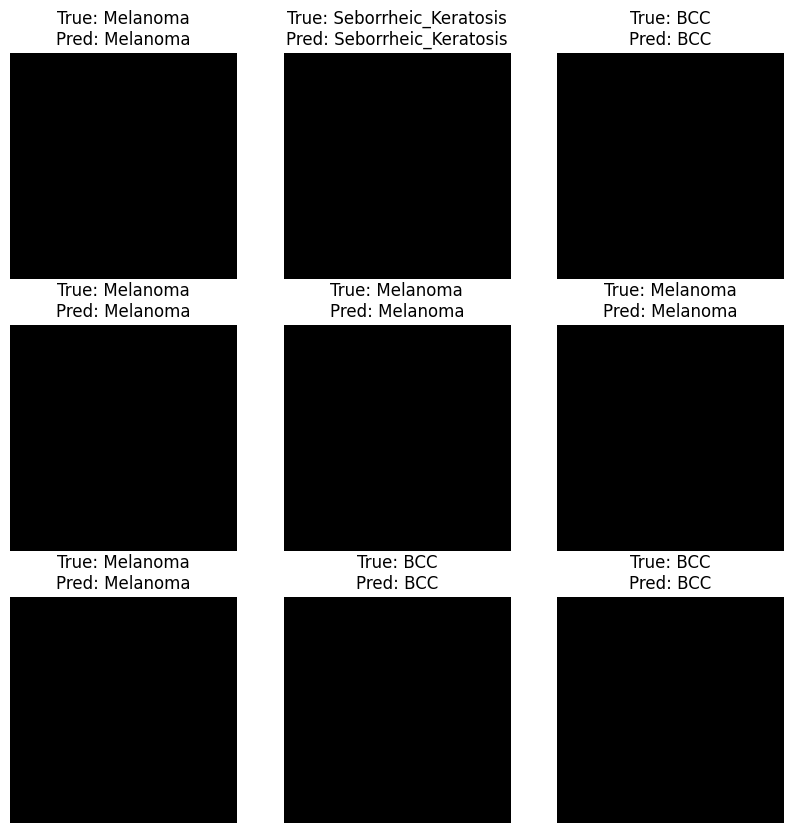

In [28]:
class_names = list(label_map.keys())

plt.figure(figsize=(10,10))
for images, labels in test_ds.take(1):
    preds = mobilenet_model.predict(images)
    for i in range(9):
        plt.subplot(3,3,i+1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(f"True: {class_names[labels[i]]}\nPred: {class_names[np.argmax(preds[i])]}")
        plt.axis("off")
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step


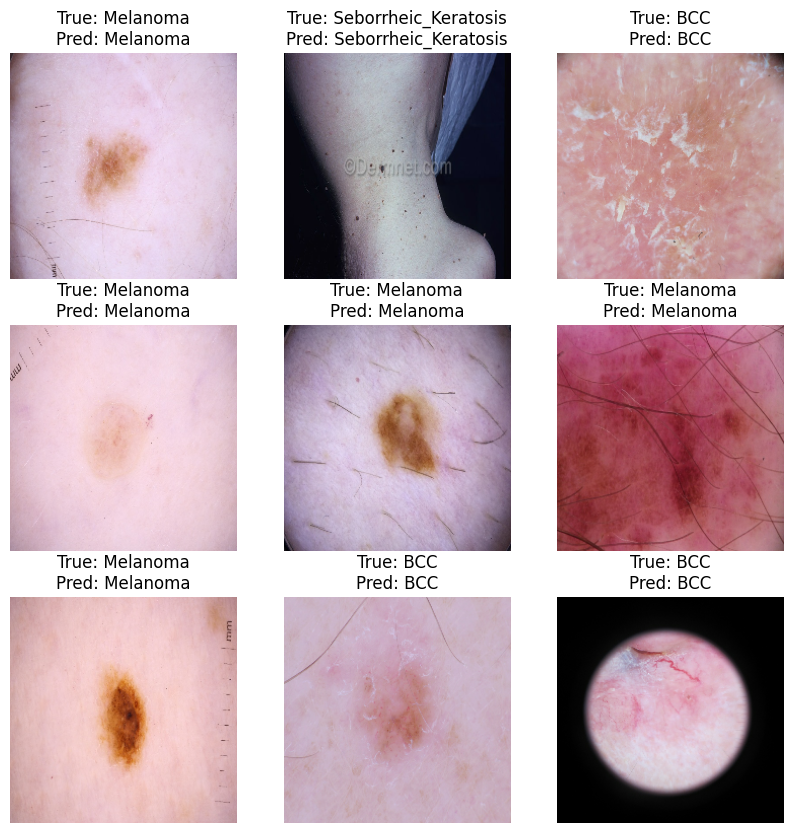

In [30]:
class_names = list(label_map.keys())

plt.figure(figsize=(10,10))

for images, labels in test_ds_mob.take(1):
    preds = mobilenet_model.predict(images)

    for i in range(9):
        plt.subplot(3,3,i+1)

        # Reverse MobileNet preprocessing
        img = images[i].numpy()
        img = (img + 1.0) / 2.0   # [-1,1] → [0,1]

        plt.imshow(img)
        plt.title(f"True: {class_names[labels[i]]}\nPred: {class_names[np.argmax(preds[i])]}")
        plt.axis("off")

plt.show()

In [29]:
mobilenet_model.save("mobilenet_model.keras")

In [ ]:
mobilenet_model.save("mobilenet_model.h5")
print("Model Saved Successfully!")

In [31]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers, models
import tensorflow as tf

# ===============================
# Dataset pipeline
# ===============================

def decode_img_mobilenet(img_path, label):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [224, 224])
    img = preprocess_input(img)   # Converts to [-1, 1]
    return img, label


def make_dataset_mobilenet(dataframe, batch=32, shuffle=True):
    paths = dataframe["image"].values
    labels = dataframe["label_idx"].values

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if shuffle:
        ds = ds.shuffle(buffer_size=len(dataframe))

    ds = ds.map(decode_img_mobilenet, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds


train_ds_mob = make_dataset_mobilenet(train_df, shuffle=True)
val_ds_mob   = make_dataset_mobilenet(val_df, shuffle=False)
test_ds_mob  = make_dataset_mobilenet(test_df, shuffle=False)


In [32]:
# ===============================
# Build MobileNetV2
# ===============================

base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

base_model.trainable = False   # Freeze all layers


mobilenet_model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.BatchNormalization(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(len(label_map), activation='softmax')
])


mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


In [33]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.3,
        patience=2,
        verbose=1
    )
]


In [34]:
history_phase1 = mobilenet_model.fit(
    train_ds_mob,
    validation_data=val_ds_mob,
    epochs=8,
    class_weight=class_weights,
    callbacks=callbacks
)


Epoch 1/8
264/264 ━━━━━━━━━━━━━━━━━━━━ 39s 113ms/step - accuracy: 0.6928 - loss: 1.0415 - val_accuracy: 0.8404 - val_loss: 0.3772 - learning_rate: 0.0010
Epoch 2/8
264/264 ━━━━━━━━━━━━━━━━━━━━ 19s 72ms/step - accuracy: 0.8334 - loss: 0.5118 - val_accuracy: 0.8632 - val_loss: 0.3396 - learning_rate: 0.0010
Epoch 3/8
264/264 ━━━━━━━━━━━━━━━━━━━━ 19s 72ms/step - accuracy: 0.8628 - loss: 0.4226 - val_accuracy: 0.8685 - val_loss: 0.3302 - learning_rate: 0.0010
Epoch 4/8
264/264 ━━━━━━━━━━━━━━━━━━━━ 19s 72ms/step - accuracy: 0.8752 - loss: 0.3805 - val_accuracy: 0.8558 - val_loss: 0.3475 - learning_rate: 0.0010
Epoch 5/8
263/264 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.8893 - loss: 0.3294
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
264/264 ━━━━━━━━━━━━━━━━━━━━ 19s 72ms/step - accuracy: 0.8893 - loss: 0.3294 - val_accuracy: 0.8706 - val_loss: 0.3380 - learning_rate: 0.0010
Epoch 6/8
264/264 ━━━━━━━━━━━━━━━━━━━━ 21s 81ms/step - accuracy: 0.9150 - loss: 0.

In [35]:
# Unfreeze model
base_model.trainable = True

# Freeze all layers except last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Recompile with LOWER learning rate
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_phase2 = mobilenet_model.fit(
    train_ds_mob,
    validation_data=val_ds_mob,
    epochs=10,
    class_weight=class_weights,
    callbacks=callbacks
)


Epoch 1/10
264/264 ━━━━━━━━━━━━━━━━━━━━ 51s 129ms/step - accuracy: 0.8053 - loss: 0.5859 - val_accuracy: 0.8578 - val_loss: 0.4804 - learning_rate: 1.0000e-05
Epoch 2/10
264/264 ━━━━━━━━━━━━━━━━━━━━ 19s 73ms/step - accuracy: 0.8507 - loss: 0.4538 - val_accuracy: 0.8625 - val_loss: 0.4567 - learning_rate: 1.0000e-05
Epoch 3/10
264/264 ━━━━━━━━━━━━━━━━━━━━ 20s 74ms/step - accuracy: 0.8622 - loss: 0.4053 - val_accuracy: 0.8712 - val_loss: 0.4125 - learning_rate: 1.0000e-05
Epoch 4/10
264/264 ━━━━━━━━━━━━━━━━━━━━ 19s 73ms/step - accuracy: 0.8851 - loss: 0.3562 - val_accuracy: 0.8739 - val_loss: 0.3848 - learning_rate: 1.0000e-05
Epoch 5/10
264/264 ━━━━━━━━━━━━━━━━━━━━ 19s 73ms/step - accuracy: 0.8928 - loss: 0.3284 - val_accuracy: 0.8732 - val_loss: 0.3617 - learning_rate: 1.0000e-05
Epoch 6/10
264/264 ━━━━━━━━━━━━━━━━━━━━ 20s 74ms/step - accuracy: 0.9005 - loss: 0.3066 - val_accuracy: 0.8706 - val_loss: 0.3438 - learning_rate: 1.0000e-05
Epoch 7/10
264/264 ━━━━━━━━━━━━━━━━━━━━ 22s 82ms/st

In [39]:
# Combine Phase 1 and Phase 2 history

acc = history_phase1.history['accuracy'] + history_phase2.history['accuracy']
val_acc = history_phase1.history['val_accuracy'] + history_phase2.history['val_accuracy']

loss = history_phase1.history['loss'] + history_phase2.history['loss']
val_loss = history_phase1.history['val_loss'] + history_phase2.history['val_loss']


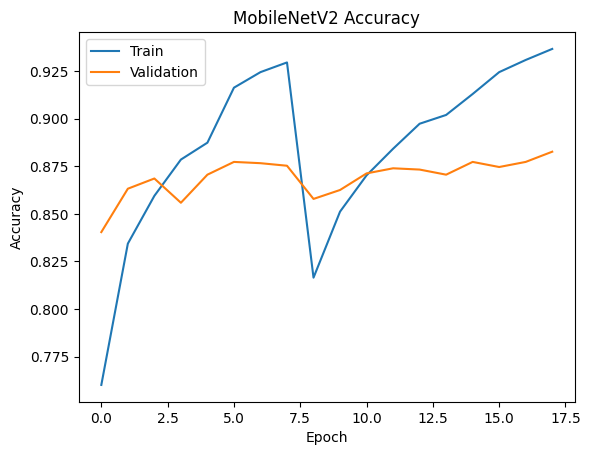

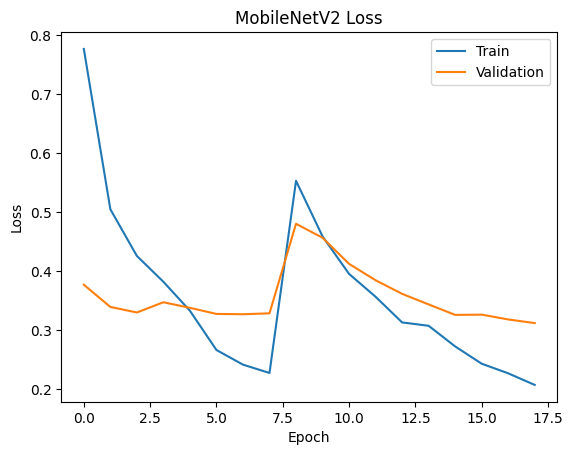

In [38]:
import matplotlib.pyplot as plt

# Accuracy Plot
plt.figure()
plt.plot(acc)
plt.plot(val_acc)
plt.title('MobileNetV2 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'])
plt.show()

# Loss Plot
plt.figure()
plt.plot(loss)
plt.plot(val_loss)
plt.title('MobileNetV2 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'])
plt.show()

In [40]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import numpy as np

# Evaluate
test_loss, test_acc = mobilenet_model.evaluate(test_ds_mob)
print("Test Accuracy:", test_acc)

# Predictions
y_true = np.concatenate([y for x, y in test_ds_mob], axis=0)
y_pred_probs = mobilenet_model.predict(test_ds_mob)
y_pred = np.argmax(y_pred_probs, axis=1)

# F1 Score
f1 = f1_score(y_true, y_pred, average='weighted')
print("Weighted F1 Score:", f1)

print("\nClassification Report:\n")
print(classification_report(y_true, y_pred))

55/55 ━━━━━━━━━━━━━━━━━━━━ 7s 123ms/step - accuracy: 0.9023 - loss: 0.3073
Test Accuracy: 0.8905358910560608
55/55 ━━━━━━━━━━━━━━━━━━━━ 12s 136ms/step
Weighted F1 Score: 0.890261817014549

Classification Report:

              precision    recall  f1-score   support

           0       0.98      0.99      0.98       499
           1       0.77      0.75      0.76       252
           2       0.99      0.97      0.98       471
           3       0.81      0.84      0.83       277
           4       0.75      0.73      0.74       255

    accuracy                           0.89      1754
   macro avg       0.86      0.86      0.86      1754
weighted avg       0.89      0.89      0.89      1754



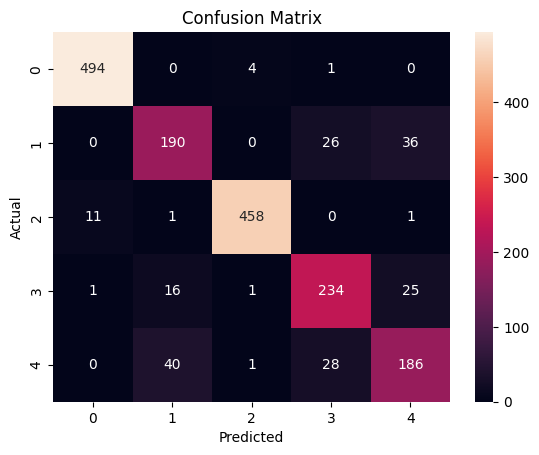

In [41]:
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure()
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


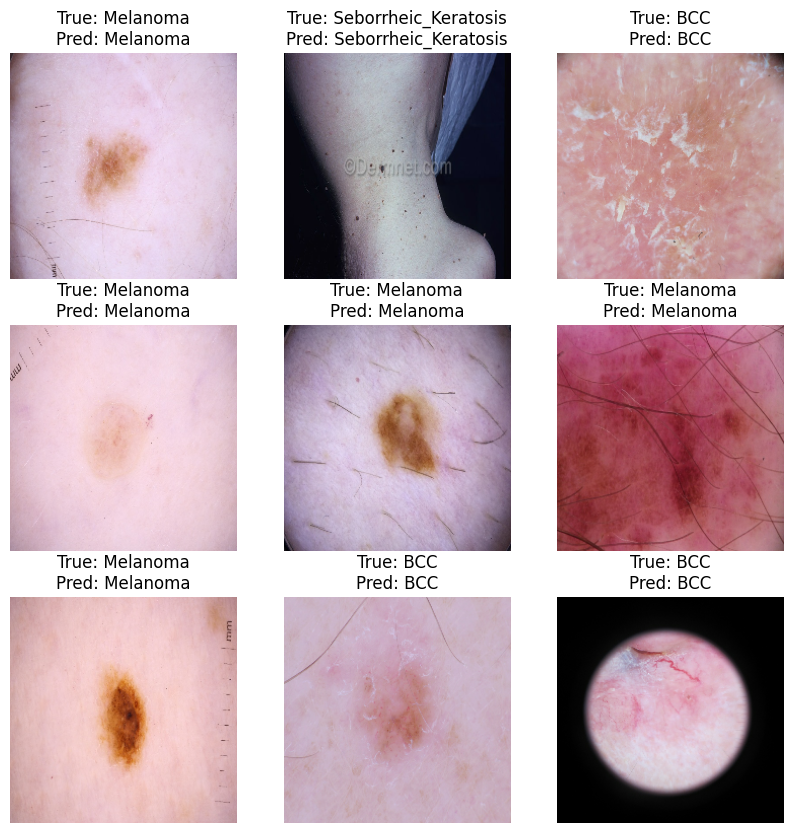

In [42]:
class_names = list(label_map.keys())

plt.figure(figsize=(10,10))

for images, labels in test_ds_mob.take(1):
    preds = mobilenet_model.predict(images)

    for i in range(9):
        plt.subplot(3,3,i+1)

        img = images[i].numpy()
        img = (img + 1.0) / 2.0   # Convert [-1,1] → [0,1]

        plt.imshow(img)
        plt.title(f"True: {class_names[labels[i]]}\nPred: {class_names[np.argmax(preds[i])]}")
        plt.axis("off")

plt.show()


In [43]:
mobilenet_model.save("skin_disease_mobilenet.keras")
print("Model saved successfully!")

Model saved successfully!


In [44]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras import layers, models
import tensorflow as tf

def decode_img_resnet(img_path, label):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [224, 224])
    img = preprocess_input(img)   # ResNet preprocessing
    return img, label


def make_dataset_resnet(dataframe, batch=32, shuffle=True):
    paths = dataframe["image"].values
    labels = dataframe["label_idx"].values

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if shuffle:
        ds = ds.shuffle(buffer_size=len(dataframe))

    ds = ds.map(decode_img_resnet, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds


train_ds_res = make_dataset_resnet(train_df, shuffle=True)
val_ds_res   = make_dataset_resnet(val_df, shuffle=False)
test_ds_res  = make_dataset_resnet(test_df, shuffle=False)


In [45]:
base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

base_model.trainable = False

resnet_model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.BatchNormalization(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(len(label_map), activation='softmax')
])

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.3,
        patience=2,
        verbose=1
    )
]

history_resnet = resnet_model.fit(
    train_ds_res,
    validation_data=val_ds_res,
    epochs=10,
    class_weight=class_weights,
    callbacks=callbacks
)


Epoch 1/10
264/264 ━━━━━━━━━━━━━━━━━━━━ 57s 161ms/step - accuracy: 0.7367 - loss: 1.0335 - val_accuracy: 0.8759 - val_loss: 0.3171 - learning_rate: 0.0010
Epoch 2/10
 34/264 ━━━━━━━━━━━━━━━━━━━━ 20s 90ms/step - accuracy: 0.8495 - loss: 0.5235

In [ ]:
from sklearn.metrics import f1_score, classification_report
import numpy as np

test_loss_res, test_acc_res = resnet_model.evaluate(test_ds_res)
print("ResNet Test Accuracy:", test_acc_res)

y_true_res = np.concatenate([y for x, y in test_ds_res], axis=0)
y_pred_probs_res = resnet_model.predict(test_ds_res)
y_pred_res = np.argmax(y_pred_probs_res, axis=1)

f1_res = f1_score(y_true_res, y_pred_res, average='weighted')
print("ResNet F1 Score:", f1_res)

print(classification_report(y_true_res, y_pred_res))


In [ ]:
def show_predictions(model):
    images, labels = next(iter(test_ds))
    preds = model.predict(images)
    preds = np.argmax(preds, axis=1)
    
    plt.figure(figsize=(12,6))
    for i in range(6):
        plt.subplot(2,3,i+1)
        plt.imshow(images[i])
        plt.title(f"True: {list(label_map.keys())[labels[i]]}\nPred: {list(label_map.keys())[preds[i]]}")
        plt.axis("off")
    plt.show()

show_predictions(best_model)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

models = ['Custom CNN', 'MobileNetV2', 'ResNet50']

accuracies = [test_acc_cnn, test_acc_mob, test_acc_res]
f1_scores  = [f1_cnn, f1_mob, f1_res]

x = np.arange(len(models))
width = 0.35

plt.figure()

plt.bar(x - width/2, accuracies, width, label='Accuracy', color='skyblue')
plt.bar(x + width/2, f1_scores, width, label='F1 Score', color='orange')

plt.xticks(x, models)
plt.ylabel('Score')
plt.title('Model Comparison: Accuracy & F1 Score')
plt.legend()

plt.show()
